# 03 · Explainability

SHAP explanations for the best tree model and term-level explanations for the review-text model (PLAN.md section 7). Run after `02_models` (it needs `main_comparison.csv` and the out-of-fold scores). This also saves the models used by the Streamlit demo.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, HTML, display, Markdown
from loanshield.common import ROOT, path, cfg
os.chdir(ROOT)                      # all paths are relative to the repo root
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_colwidth", 60, "display.max_columns", 30)
print("repo:", ROOT)

from loanshield.explain import shap_report
N_ITER = int(os.environ.get("LOANSHIELD_N_ITER", 30))
card = shap_report.run(N_ITER)   # also writes results/models/model_card.json for the demo and report
card

repo: C:\Users\HARDIK\Desktop\New folder\loanshield


17:29:18 INFO splits: dataset features: 414 apps, 50 unverified, 366 developers, 53 features


17:29:18 INFO shap_report: explaining best tree model by grouped-CV PR-AUC on organic apps: rf


17:30:00 INFO shap_report: tabular: rf, inner AP 0.413, top features ['mentions_partner', 'app_age_days', 'states_tenure', 'log_desc_len', 'log_rev_count']


17:30:00 INFO splits: dataset features: 414 apps, 50 unverified, 366 developers, 53 features


{'created': '2026-10-11T17:29:18',
 'calibration': 'platt_on_oof',
 'verdict_threshold': 0.16768925831700743,
 'oof_pr_auc': 0.31175065687156267,
 'tabular_model': 'rf',
 'tabular_params': {'n_estimators': '400',
  'min_samples_leaf': '4',
  'max_features': '0.3',
  'max_depth': 'None'},
 'tabular_inner_ap': np.float64(0.4134808473041593),
 'n_apps': 414,
 'n_unverified': 50,
 'text_model': 'tfidf_lr',
 'n_reviews': 47177,
 'labels_md5': 'f215f0cf2b',
 'positive_class': 'unverified'}

## Global feature importance

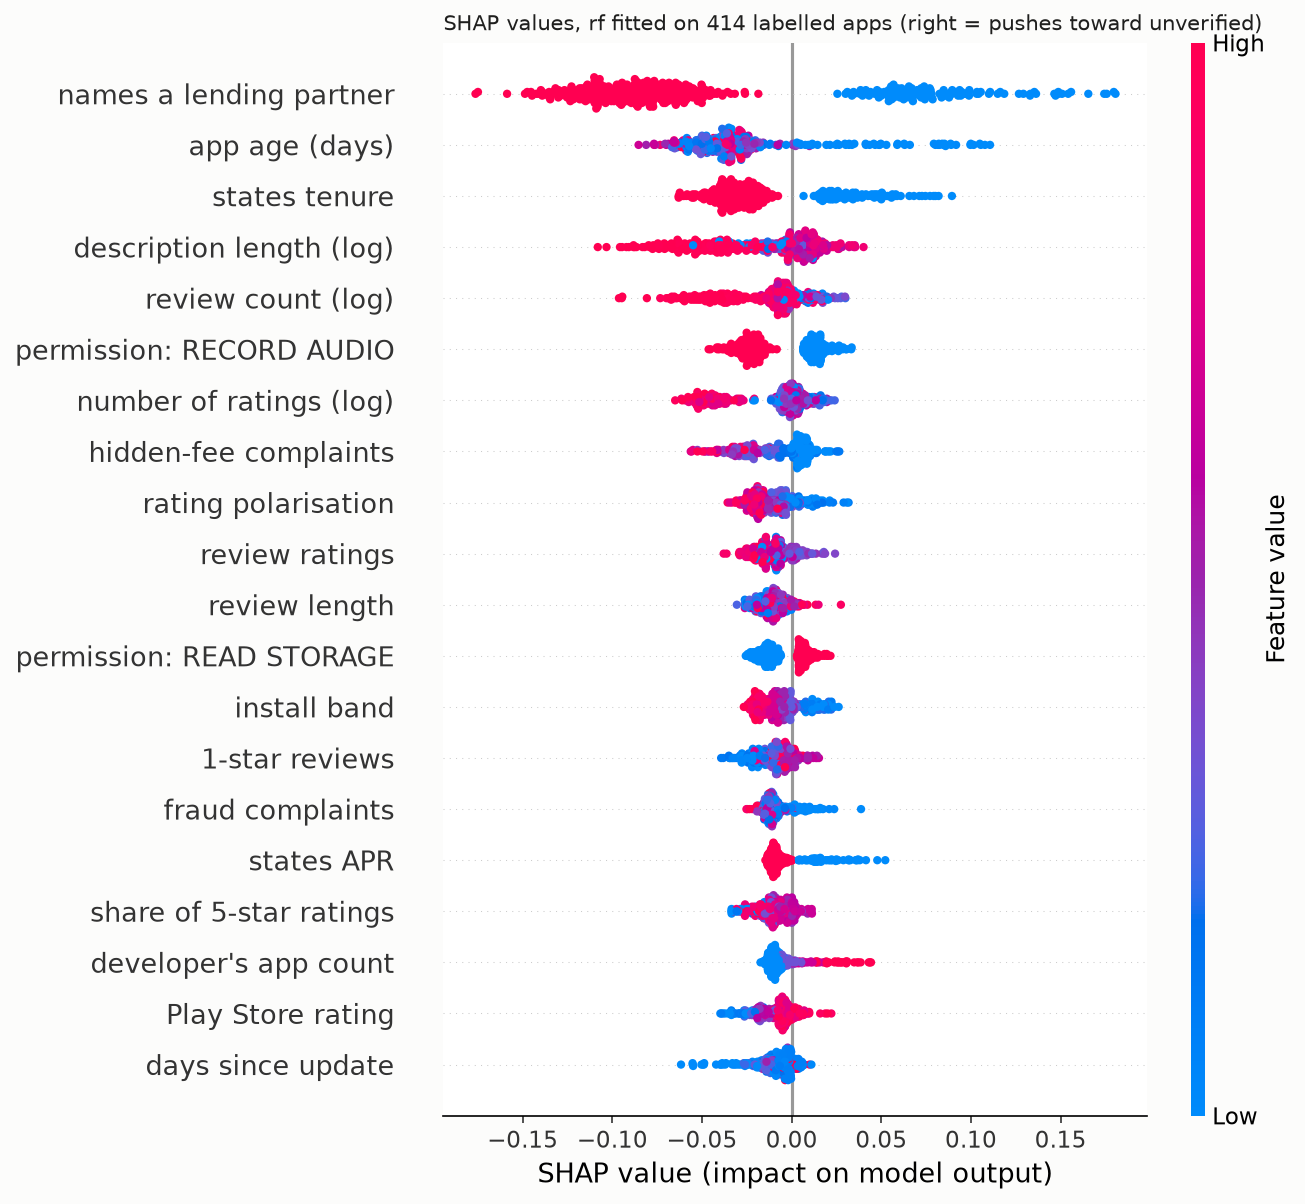

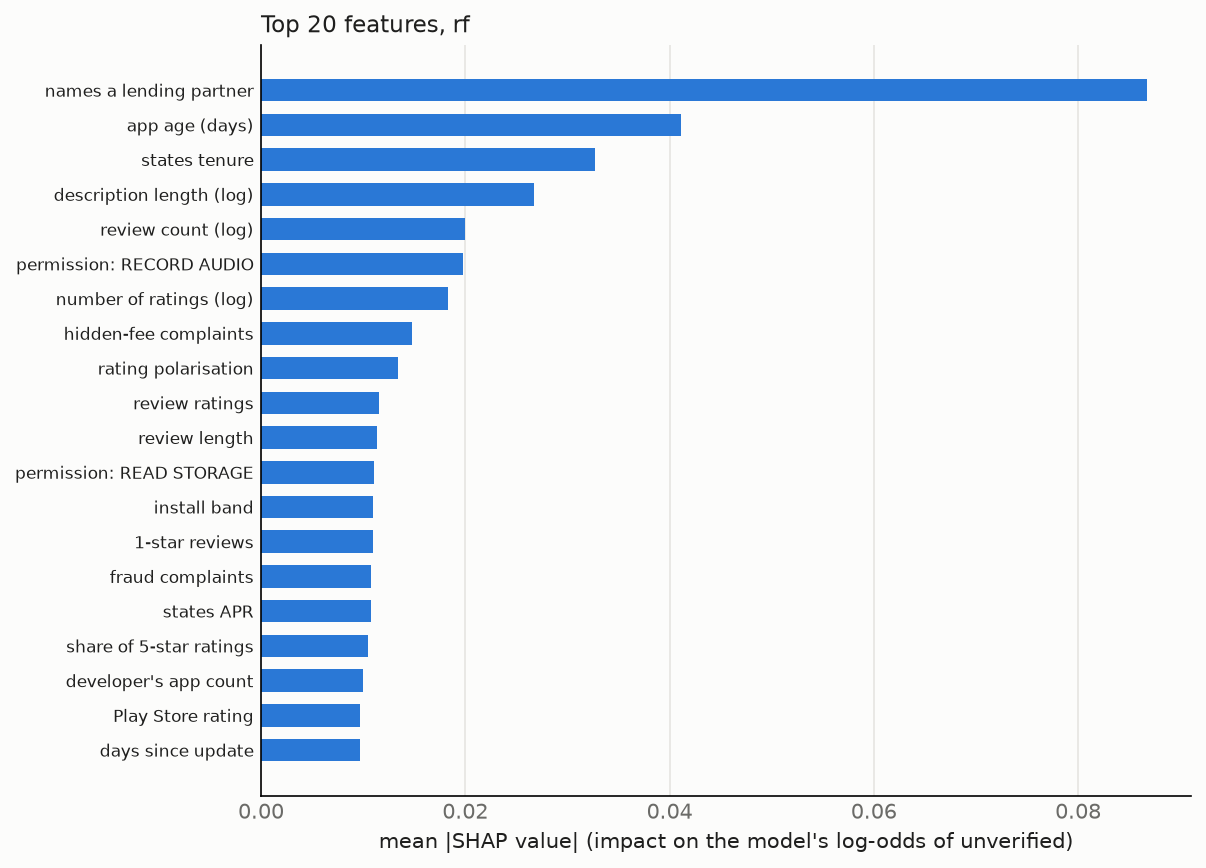

,feature,mean_abs_shap
0,mentions_partner,0.086719
1,app_age_days,0.041124
2,states_tenure,0.032685
3,log_desc_len,0.026754
4,log_rev_count,0.019939
5,perm_RECORD_AUDIO,0.019801
6,log_ratings,0.018279
7,rev_share_fee,0.014778
8,polarisation,0.013420
9,rev_mean_score,0.011589


In [2]:
display(Image(str(path("results", "figures", "shap_summary_beeswarm.png"))))
display(Image(str(path("results", "figures", "shap_bar_top20.png"))))
imp = pd.read_csv(path("results", "tables", "shap_importance.csv"))
imp.head(20)

## Dependence plots (top 3 features)

**app_age_days**

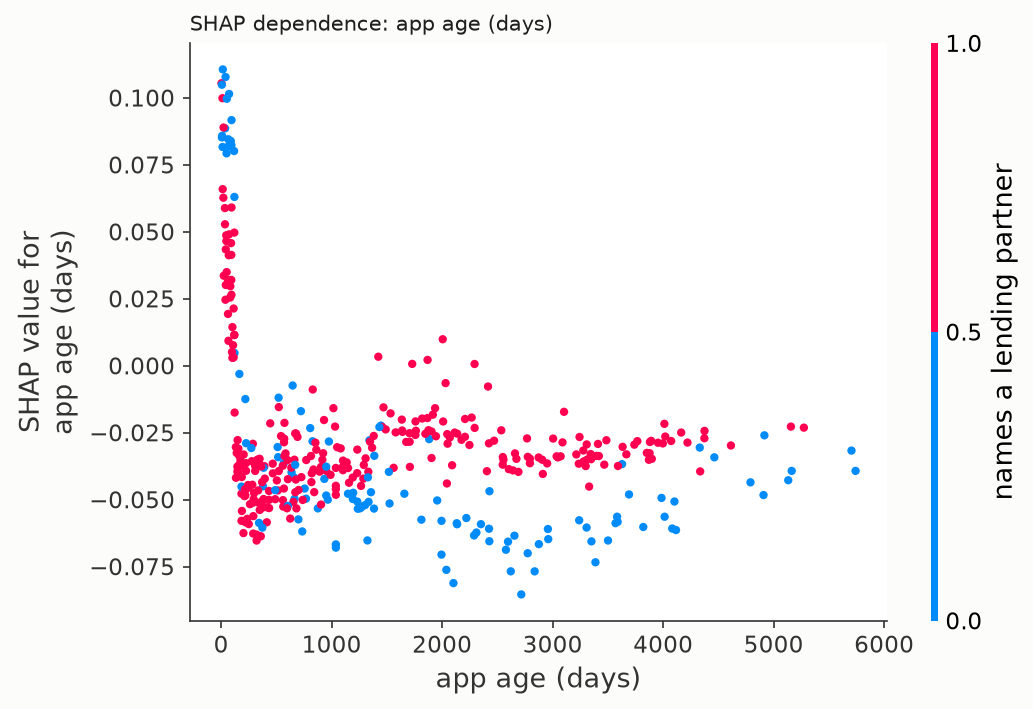

**mentions_partner**

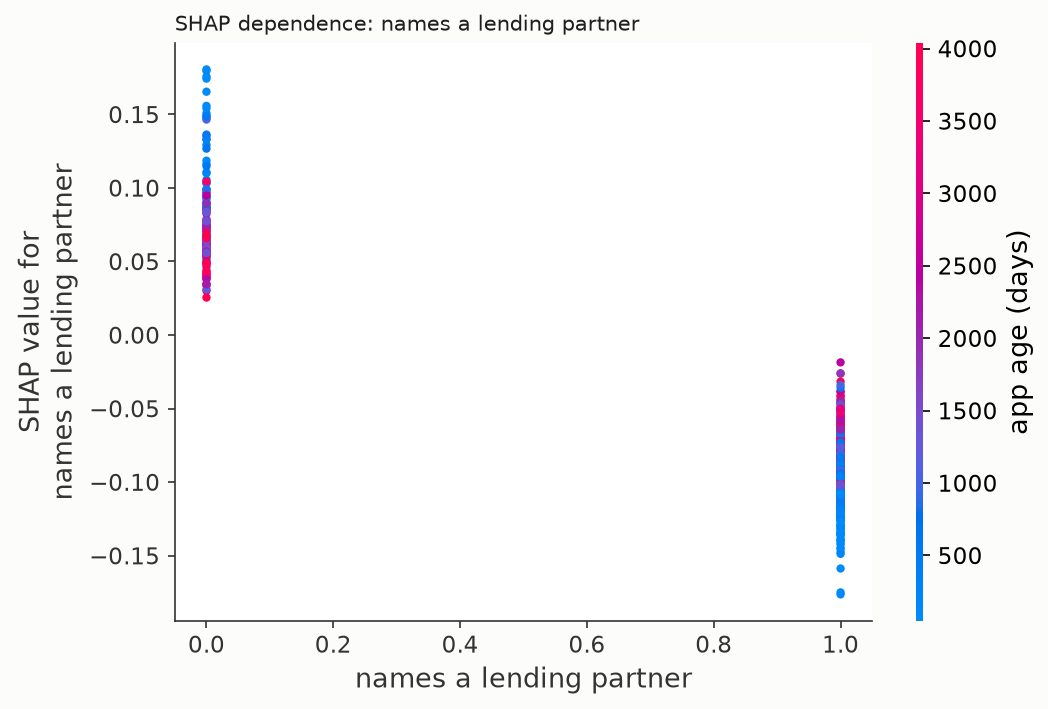

**states_tenure**

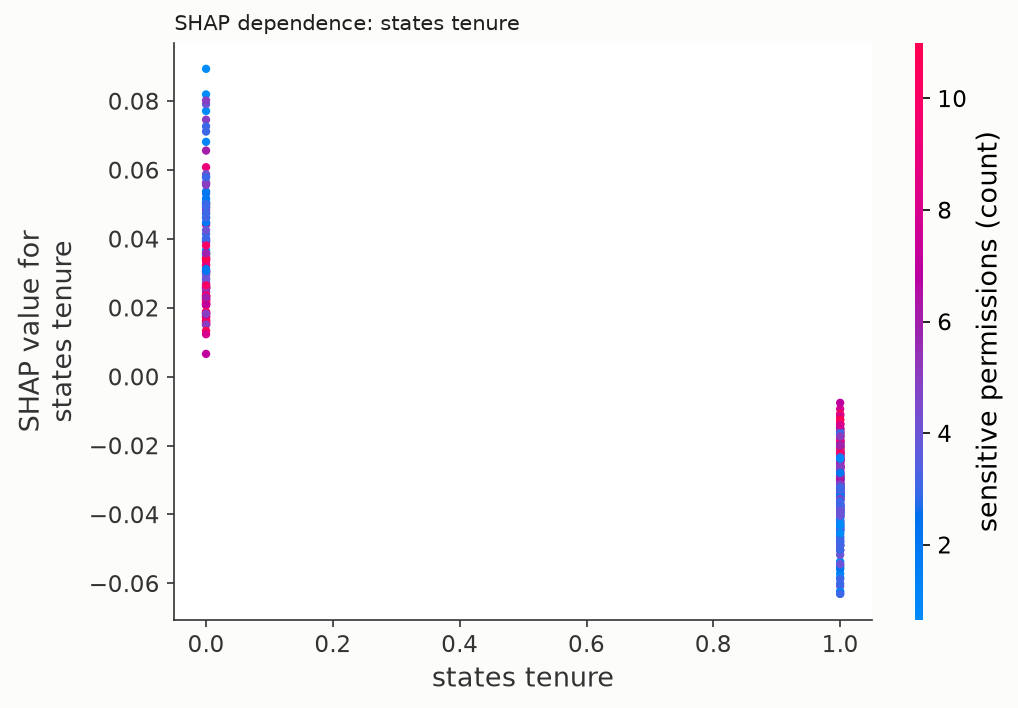

In [3]:
for f in sorted(path("results", "figures").glob("shap_dependence_*.png")):
    display(Markdown(f"**{f.stem.removeprefix('shap_dependence_')}**")); display(Image(str(f)))

## Per-app explanations
The model's top 3 reasons in each direction, in plain language. Risk scores are **out-of-fold** (the app was not in the training fold). The highest-scoring apps:

In [4]:
ex = pd.read_csv(path("results", "tables", "app_explanations.csv"))
display(ex.head(10)[["title", "label", "risk_score_oof", "warning_1", "warning_2", "warning_3"]])
print("Verified apps the model scores highest (false-positive candidates):")
display(ex[ex.label == "verified"].head(5)[["title", "risk_score_oof", "warning_1", "warning_2"]])

,title,label,risk_score_oof,warning_1,warning_2,warning_3
0,EasyLend-Revolving Credit,unverified,0.780000,Does not name an NBFC or bank lending partner,Released 68 days ago,Does not state the loan tenure
1,Furtila Rupee-Smart Credit,unverified,0.718139,Does not name an NBFC or bank lending partner,Released 7 days ago,Does not request your microphone
2,FlexeRupee:Credit Line,unverified,0.695845,Does not name an NBFC or bank lending partner,Released 7 days ago,Does not state the loan tenure
3,neo for corporates,verified,0.695000,Does not name an NBFC or bank lending partner,Does not state the loan tenure,Does not request your microphone
4,RevoLine: Quick Credit Line,unverified,0.670996,Does not name an NBFC or bank lending partner,Does not state the loan tenure,Does not request your microphone
5,RupeeLoop Loan-Line of credit,unverified,0.560511,Does not name an NBFC or bank lending partner,Released 117 days ago,Does not state the loan tenure
6,CashOne,verified,0.533926,Does not name an NBFC or bank lending partner,Does not request your microphone,No urgency phrases
7,FinGrow,verified,0.515078,Released 36 days ago,Does not name an NBFC or bank lending partner,Does not state the loan tenure
8,4Fin,verified,0.497971,Does not name an NBFC or bank lending partner,Does not state the loan tenure,Does not request your microphone
9,Petro1 by Tyger Capital,verified,0.488116,Released 51 days ago,Does not name an NBFC or bank lending partner,Does not state the loan tenure


Verified apps the model scores highest (false-positive candidates):


,title,risk_score_oof,warning_1,warning_2
3,neo for corporates,0.695000,Does not name an NBFC or bank lending partner,Does not state the loan tenure
6,CashOne,0.533926,Does not name an NBFC or bank lending partner,Does not request your microphone
7,FinGrow,0.515078,Released 36 days ago,Does not name an NBFC or bank lending partner
8,4Fin,0.497971,Does not name an NBFC or bank lending partner,Does not state the loan tenure
9,Petro1 by Tyger Capital,0.488116,Released 51 days ago,Does not name an NBFC or bank lending partner


## Review-text model
Highest-weight n-grams per class (TF-IDF + logistic regression on all labelled apps' reviews). Check whether the "unverified" terms are risk language or just app and product names. Names mean the model is memorising apps.

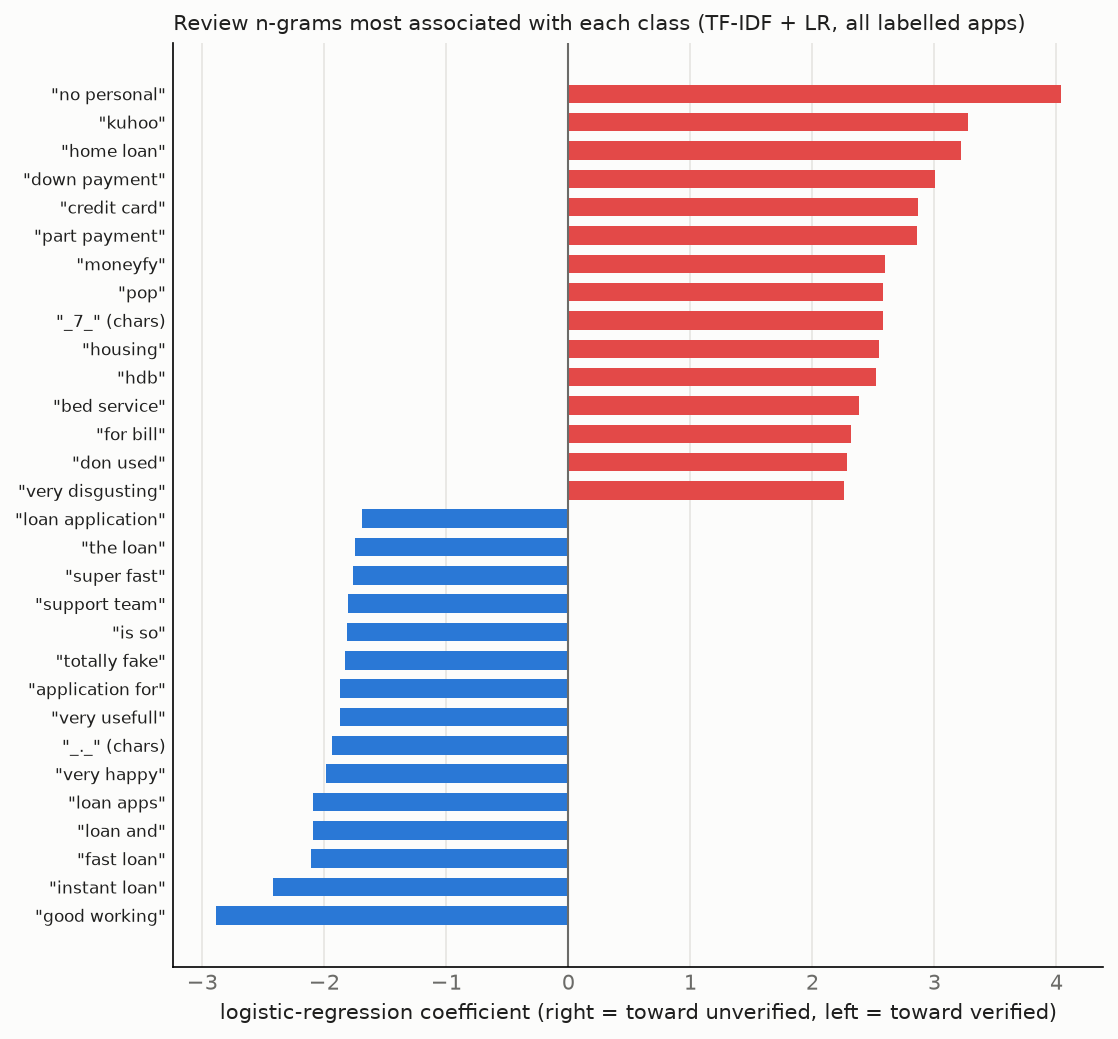

,unverified_term,unverified_coef,verified_term,verified_coef
0,word__no personal,4.037493,word__good working,-2.890842
1,word__kuhoo,3.272962,word__instant loan,-2.419625
2,word__home loan,3.219722,word__fast loan,-2.108758
3,word__down payment,3.003312,word__loan and,-2.096073
4,word__credit card,2.867961,word__loan apps,-2.090007
5,word__part payment,2.861294,word__very happy,-1.983323
6,word__moneyfy,2.598964,char__ .,-1.936599
7,word__pop,2.574915,word__very usefull,-1.872088
8,char__ 7,2.574647,word__application for,-1.869718
9,word__housing,2.542795,word__totally fake,-1.832396


In [5]:
display(Image(str(path("results", "figures", "shap_text_top_terms.png"))))
display(pd.read_csv(path("results", "tables", "text_top_terms.csv")).head(15))

In [6]:
display(HTML(path("results", "figures", "text_examples.html").read_text(encoding="utf-8")))